 # E-Commerce Sales Analysis for an Online Store

This mini project presents a comprehensive analysis of sales data from a UK-based e-commerce store. The purpose is to clean, analyze, and interpret online transaction records using the Pandas library in Python. The analysis aims to uncover business insights and provide data-driven recommendations for e-commerce optimization.

#### 1. OBJECTIVES

- Clean and preprocess the raw dataset using Pandas
- Analyze sales trends and customer behavior
- Identify top-performing products and peak sales periods
- Visualize key metrics using Python's Matplotlib/Seaborn
- Develop actionable business recommendations based on findings

#### 2. DATASET DESCRIPTION

The dataset used for this project is sourced from Kaggle and contains real e-commerce transaction data from a UK-based online retailer. The data includes fields such as InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, and Country.

#### 3. DATA CLEANING AND PREPARATION

Data cleaning steps performed:
- Removed null and duplicate rows
- Converted InvoiceDate to datetime format
- Filtered out records with negative quantities or prices
- Created a new 'TotalPrice' column (Quantity × UnitPrice)
- Extracted month and hour from InvoiceDate for time-based analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('data.csv', encoding='ISO-8859-1')  # we use encoding='ISO-8859-1' because file not encoded in UTF-8

##### Get dataframe overview

In [3]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [5]:
df.head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


In [6]:
df.count()

InvoiceNo      541909
StockCode      541909
Description    540455
Quantity       541909
InvoiceDate    541909
UnitPrice      541909
CustomerID     406829
Country        541909
dtype: int64

In [7]:
df.shape

(541909, 8)

In [8]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,12680.0,France


##### Cleaning Data

In [9]:
df.dtypes

InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object

In [10]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%m/%d/%Y %H:%M')
df['InvoiceDate']

0        2010-12-01 08:26:00
1        2010-12-01 08:26:00
2        2010-12-01 08:26:00
3        2010-12-01 08:26:00
4        2010-12-01 08:26:00
                 ...        
541904   2011-12-09 12:50:00
541905   2011-12-09 12:50:00
541906   2011-12-09 12:50:00
541907   2011-12-09 12:50:00
541908   2011-12-09 12:50:00
Name: InvoiceDate, Length: 541909, dtype: datetime64[ns]

In [11]:
df['CustomerID'] = df['CustomerID'].astype('str')
df['CustomerID']

0         17850.0
1         17850.0
2         17850.0
3         17850.0
4         17850.0
           ...   
541904    12680.0
541905    12680.0
541906    12680.0
541907    12680.0
541908    12680.0
Name: CustomerID, Length: 541909, dtype: object

In [12]:
df.isnull().sum()

InvoiceNo         0
StockCode         0
Description    1454
Quantity          0
InvoiceDate       0
UnitPrice         0
CustomerID        0
Country           0
dtype: int64

In [13]:
df['Description'].unique()

array(['WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN',
       'CREAM CUPID HEARTS COAT HANGER', ..., 'lost',
       'CREAM HANGING HEART T-LIGHT HOLDER',
       'PAPER CRAFT , LITTLE BIRDIE'], shape=(4224,), dtype=object)

In [14]:
df['StockCode'].unique()

array(['85123A', '71053', '84406B', ..., '90214U', '47591b', '23843'],
      shape=(4070,), dtype=object)

In [15]:
# https://www.kaggle.com/code/duygujones/customer-behaviour-analysis-eda-rfm-pca
# study link ni,padu EDA dia
#dont feel overwhemlmed. bkn hg xpandai cuma kurang membaca and praktis ja. U can do this. First step mmg susah terox but in the end it sgt2 easy.

In [16]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853


Numerical Features:

- Outliers Detected: There are clear outliers in both Quantity and UnitPrice that need to be addressed.
- Negative Values: Negative values in Quantity and UnitPrice are present, likely due to cancelled transactions.
- Missing Values: Missing data is observed in CustomerID and Description, which will require handling.
- Derived Feature: Quantity and UnitPrice should be multiplied to create a new feature, Total Price.

In [17]:
df.describe(include = 'all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,541909,4373,nan,135080,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
df['Description'].isnull().sum()


np.int64(1454)

In [19]:
df.drop_duplicates(keep='first', inplace=True) #Now df is changed directly

In [20]:
df.isnull().sum()

InvoiceNo         0
StockCode         0
Description    1454
Quantity          0
InvoiceDate       0
UnitPrice         0
CustomerID        0
Country           0
dtype: int64

In [21]:
df[df['Description'].isna() | df['StockCode'].isna()]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,nan,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,nan,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,nan,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,nan,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,nan,United Kingdom
...,...,...,...,...,...,...,...,...
535322,581199,84581,NaN,-2,2011-12-07 18:26:00,0.0,nan,United Kingdom
535326,581203,23406,NaN,15,2011-12-07 18:31:00,0.0,nan,United Kingdom
535332,581209,21620,NaN,6,2011-12-07 18:35:00,0.0,nan,United Kingdom
536981,581234,72817,NaN,27,2011-12-08 10:33:00,0.0,nan,United Kingdom


In [22]:
# Find 'StockCodes' with multiple unique 'Descriptions'
df.groupby(['StockCode','Description']).size().reset_index(name='Count').head(30) 
# size() show how much pair of Stockcode and Description appear together.
# .reset_index(name='Count') eliminate index num sedia ada paling kiri. Then, paling kanan dia rename as Count.

,StockCode,Description,Count
0,10002,INFLATABLE POLITICAL GLOBE,71
1,10080,GROOVY CACTUS INFLATABLE,22
2,10080,check,1
3,10120,DOGGY RUBBER,29
4,10123C,HEARTS WRAPPING TAPE,3
5,10124A,SPOTS ON RED BOOKCOVER TAPE,5
6,10124G,ARMY CAMO BOOKCOVER TAPE,4
7,10125,MINI FUNKY DESIGN TAPES,93
8,10133,COLOURING PENCILS BROWN TUBE,197
9,10133,damaged,1


In [23]:
# Removing rows with missing values in 'CustomerID' and 'Description' columns
df.dropna(subset=['StockCode','Description'],inplace=True)

In [24]:
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [25]:
df = df[df['Quantity'] > 0]

In [26]:
df = df[df['UnitPrice'] > 0]

In [27]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [28]:
df.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID             object
Country                object
dtype: object

In [29]:
df['InvoiceMonth'] = df['InvoiceDate'].dt.month     # 1 to 12
df['InvoiceHour'] = df['InvoiceDate'].dt.hour       # 0 to 23

In [30]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceMonth,InvoiceHour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,12,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,12,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,12,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,12,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,12,8


In [31]:
df['Description'].unique()

array(['WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN',
       'CREAM CUPID HEARTS COAT HANGER', ..., 'LETTER "U" BLING KEY RING',
       'CREAM HANGING HEART T-LIGHT HOLDER',
       'PAPER CRAFT , LITTLE BIRDIE'], shape=(4026,), dtype=object)

In [32]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvoiceMonth,InvoiceHour,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,12,8,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,12,8,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,12,8,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,12,8,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,12,8,20.34


In [33]:
#removing Nan is CustomerID

df = df[df['CustomerID'] != 'nan']

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 392692 entries, 0 to 541908
Data columns (total 11 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   InvoiceNo     392692 non-null  object        
 1   StockCode     392692 non-null  object        
 2   Description   392692 non-null  object        
 3   Quantity      392692 non-null  int64         
 4   InvoiceDate   392692 non-null  datetime64[ns]
 5   UnitPrice     392692 non-null  float64       
 6   CustomerID    392692 non-null  object        
 7   Country       392692 non-null  object        
 8   InvoiceMonth  392692 non-null  int32         
 9   InvoiceHour   392692 non-null  int32         
 10  TotalPrice    392692 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int32(2), int64(1), object(5)
memory usage: 33.0+ MB


### Exploratory Data Analysis

1. Which products are best-selling?

In [35]:
# Answer: WHITE HANGING HEART T-LIGHT HOLDER

In [47]:
BestSelling = df.groupby(['Description']).size().reset_index(name='Count').sort_values(by='Count', ascending=False).reset_index(drop=True)
BestSelling

,Description,Count
0,WHITE HANGING HEART T-LIGHT HOLDER,2016
1,REGENCY CAKESTAND 3 TIER,1713
2,JUMBO BAG RED RETROSPOT,1615
3,ASSORTED COLOUR BIRD ORNAMENT,1395
4,PARTY BUNTING,1389
...,...,...
3872,BLUE/YELLOW CERAMIC CANDLE HOLDER,1
3873,BLUE/NAT SHELL NECKLACE W PENDANT,1
3874,BLUE/GREEN SHELL NECKLACE W PENDANT,1
3875,WRAP BLUE RUSSIAN FOLKART,1


2.  What are the peak months and hours for sales?

In [49]:
# Peak month for sale is November


df.groupby('InvoiceMonth')['TotalPrice'].sum().reset_index().sort_values(by= 'TotalPrice', ascending= False ).reset_index(drop=True)

,InvoiceMonth,TotalPrice
0,11,1156205.610
1,12,1087613.170
2,10,1035642.450
3,9,950690.202
4,5,677355.150
5,6,660046.050
6,8,644051.040
7,7,598962.901
8,3,594081.760
9,1,568101.310


In [50]:
# Peak hour for sale is 12 00

df.groupby('InvoiceHour')['TotalPrice'].sum().reset_index().sort_values(by= 'TotalPrice', ascending= False ).reset_index(drop=True)

,InvoiceHour,TotalPrice
0,12,1373695.390
1,10,1259267.591
2,13,1168724.200
3,11,1101177.600
4,14,991992.821
5,15,963559.680
6,9,842392.341
7,16,467380.560
8,8,281997.790
9,17,233811.591


3. What countries have the highest order volume?

In [53]:
#Highest order volume is United Kingdom

CountriesHighest = df.groupby('Country')['Quantity'].sum().reset_index().sort_values(by= 'Quantity', ascending= False ).reset_index(drop=True)
CountriesHighest

,Country,Quantity
0,United Kingdom,4241305
1,Netherlands,200361
2,EIRE,140133
3,Germany,119154
4,France,111428
5,Australia,83891
6,Sweden,36078
7,Switzerland,30082
8,Spain,27933
9,Japan,26016


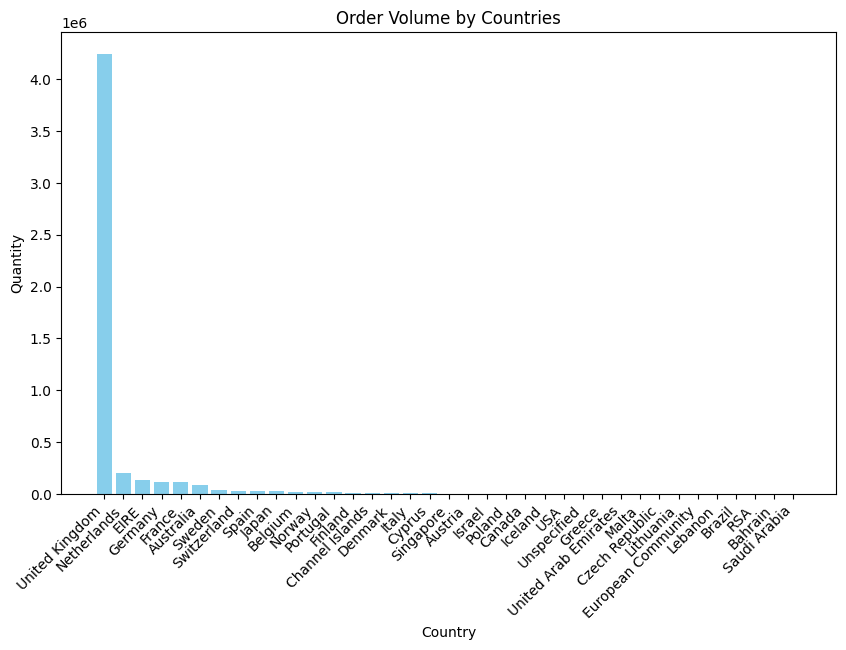

In [57]:
# Extract labels and values
labels = CountriesHighest['Country']
counts = CountriesHighest['Quantity']

# Plot
plt.figure(figsize=(10, 6))
plt.bar(labels, counts, color='skyblue')

# Add labels and title
plt.xlabel('Country')
plt.ylabel('Quantity')
plt.title('Order Volume by Countries')
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability

plt.tight_layout()
plt.show()

4. Are there frequent customers?

In [52]:
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': 'max',
    'InvoiceNo': 'nunique'
}).rename(columns={'InvoiceDate': 'LastPurchase', 'InvoiceNo': 'Frequency'}).sort_values(by='Frequency',ascending=False)
rfm

,LastPurchase,Frequency
CustomerID,,
12748.0,2011-12-09 12:20:00,209
14911.0,2011-12-08 15:54:00,201
17841.0,2011-12-08 12:07:00,124
13089.0,2011-12-07 09:02:00,97
14606.0,2011-12-08 19:28:00,93
...,...,...
18213.0,2011-04-17 10:21:00,1
18215.0,2011-09-11 16:05:00,1
18269.0,2010-12-08 13:53:00,1
